In [75]:
import pandas as pd
import numpy as np
import matplotlib as plt
import seaborn as sns

# for the count plot and bar plot
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

In [17]:
df = pd.read_csv("US_Accidents_March23_sampled_500k.csv")
df.describe()

,Severity,Start_Lat,Start_Lng,End_Lat,End_Lng,Distance(mi),Temperature(F),Wind_Chill(F),Humidity(%),Pressure(in),Visibility(mi),Wind_Speed(mph),Precipitation(in)
count,500000.000000,500000.000000,500000.000000,279623.000000,279623.000000,500000.000000,489534.000000,370983.000000,488870.000000,491072.000000,488709.000000,463013.000000,357384.000000
mean,2.212748,36.206421,-94.736583,36.273192,-95.776553,0.564317,61.646254,58.229028,64.834921,29.536621,9.091540,7.681347,0.008289
std,0.486661,5.071411,17.405761,5.265333,18.120211,1.774872,19.000133,22.352246,22.826158,1.008666,2.708083,5.431361,0.101865
min,1.000000,24.562117,-124.497420,24.570110,-124.497419,0.000000,-77.800000,-53.200000,1.000000,0.120000,0.000000,0.000000,0.000000
25%,2.000000,33.416823,-117.233047,33.474773,-117.778324,0.000000,49.000000,43.000000,48.000000,29.370000,10.000000,4.600000,0.000000
50%,2.000000,35.832147,-87.794365,36.192669,-88.039013,0.029000,64.000000,62.000000,67.000000,29.860000,10.000000,7.000000,0.000000
75%,2.000000,40.082443,-80.359601,40.181341,-80.252449,0.465000,76.000000,75.000000,84.000000,30.030000,10.000000,10.400000,0.000000
max,4.000000,48.999569,-67.484130,48.998901,-67.484130,193.479996,207.000000,207.000000,100.000000,38.440000,130.000000,822.800000,10.130000


In [18]:
# const value 
FILL_NA_VALUE = "NA"
ZERO = 0
# dropping and filling NA
dfClean = df.drop(["ID", "End_Lat", "End_Lng", "Wind_Chill(F)", "Airport_Code"], axis=1)
# fill string null with "NA"
dfClean["Description"] = dfClean["Description"].fillna(FILL_NA_VALUE)
dfClean["Street"] = dfClean["Street"].fillna(FILL_NA_VALUE)
dfClean["City"] = dfClean["City"].fillna(FILL_NA_VALUE)
dfClean["Zipcode"] = dfClean["Zipcode"].fillna(FILL_NA_VALUE)
dfClean["Timezone"] = dfClean["Timezone"].fillna(FILL_NA_VALUE)
dfClean["Weather_Timestamp"] = dfClean["Weather_Timestamp"].fillna(FILL_NA_VALUE)
dfClean["Wind_Direction"] = dfClean["Wind_Direction"].fillna(FILL_NA_VALUE)
dfClean["Weather_Condition"] = dfClean["Weather_Condition"].fillna(FILL_NA_VALUE)
dfClean["Sunrise_Sunset"] = dfClean["Sunrise_Sunset"].fillna(FILL_NA_VALUE)
dfClean["Civil_Twilight"] = dfClean["Civil_Twilight"].fillna(FILL_NA_VALUE)
dfClean["Nautical_Twilight"] = dfClean["Nautical_Twilight"].fillna(FILL_NA_VALUE)
dfClean["Astronomical_Twilight"] = dfClean["Astronomical_Twilight"].fillna(FILL_NA_VALUE)

# fill float NA with mean
dfClean["Temperature(F)"] = dfClean["Temperature(F)"].fillna(dfClean["Temperature(F)"].mean())
dfClean["Humidity(%)"] = dfClean["Humidity(%)"].fillna(dfClean["Humidity(%)"].mean())
dfClean["Pressure(in)"] = dfClean["Pressure(in)"].fillna(dfClean["Pressure(in)"].mean())
dfClean["Visibility(mi)"] = dfClean["Visibility(mi)"].fillna(dfClean["Visibility(mi)"].mean())
dfClean["Wind_Speed(mph)"] = dfClean["Wind_Speed(mph)"].fillna(dfClean["Wind_Speed(mph)"].mean())
dfClean["Precipitation(in)"] = dfClean["Precipitation(in)"].fillna(ZERO)

dfClean.info()


<class 'pandas.DataFrame'>
RangeIndex: 500000 entries, 0 to 499999
Data columns (total 41 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   Source                 500000 non-null  str    
 1   Severity               500000 non-null  int64  
 2   Start_Time             500000 non-null  str    
 3   End_Time               500000 non-null  str    
 4   Start_Lat              500000 non-null  float64
 5   Start_Lng              500000 non-null  float64
 6   Distance(mi)           500000 non-null  float64
 7   Description            500000 non-null  str    
 8   Street                 500000 non-null  str    
 9   City                   500000 non-null  str    
 10  County                 500000 non-null  str    
 11  State                  500000 non-null  str    
 12  Zipcode                500000 non-null  str    
 13  Country                500000 non-null  str    
 14  Timezone               500000 non-null  str    

In [19]:
# Columns used to identify potential duplicate accidents, this was discovered upon realizing certain wind speed entries where duplicated 
duplicate_columns = [
    'Start_Time',
    'Start_Lat',
    'Start_Lng'
]

# Mark rows that share these values  (True = part of a duplicate group)
is_duplicate = dfClean.duplicated(
    subset=duplicate_columns,
    keep=False
)

# Use the True/False mark determine which rows are duplicates
duplicates = dfClean[is_duplicate].copy()


# Sort so each duplicate group appears together
duplicates = duplicates.sort_values(by=duplicate_columns)

# Drops duplicates in data set, only keeps first occurence of every entry found
dfClean = dfClean.drop_duplicates(subset=duplicate_columns, keep='first')
dfClean.info()

<class 'pandas.DataFrame'>
Index: 497758 entries, 0 to 499999
Data columns (total 41 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   Source                 497758 non-null  str    
 1   Severity               497758 non-null  int64  
 2   Start_Time             497758 non-null  str    
 3   End_Time               497758 non-null  str    
 4   Start_Lat              497758 non-null  float64
 5   Start_Lng              497758 non-null  float64
 6   Distance(mi)           497758 non-null  float64
 7   Description            497758 non-null  str    
 8   Street                 497758 non-null  str    
 9   City                   497758 non-null  str    
 10  County                 497758 non-null  str    
 11  State                  497758 non-null  str    
 12  Zipcode                497758 non-null  str    
 13  Country                497758 non-null  str    
 14  Timezone               497758 non-null  str    
 15 

In [20]:
# Wind Speed Outliers Removal

# Wind speeds over 100 are unrealistic 
MAX_WIND_SPEED = 100

wind_speed_outliers = dfClean[dfClean['Wind_Speed(mph)'] > MAX_WIND_SPEED]
# Cleans dataset to only have wind speeds below 100 mph
dfClean = dfClean[(dfClean['Wind_Speed(mph)'] <= MAX_WIND_SPEED)]
print("Highest wind speed now:", dfClean['Wind_Speed(mph)'].max())


Highest wind speed now: 82.0


In [31]:
dfClean.info()

<class 'pandas.DataFrame'>
Index: 497751 entries, 0 to 499999
Data columns (total 41 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   Source                 497751 non-null  str    
 1   Severity               497751 non-null  int64  
 2   Start_Time             497751 non-null  str    
 3   End_Time               497751 non-null  str    
 4   Start_Lat              497751 non-null  float64
 5   Start_Lng              497751 non-null  float64
 6   Distance(mi)           497751 non-null  float64
 7   Description            497751 non-null  str    
 8   Street                 497751 non-null  str    
 9   City                   497751 non-null  str    
 10  County                 497751 non-null  str    
 11  State                  497751 non-null  str    
 12  Zipcode                497751 non-null  str    
 13  Country                497751 non-null  str    
 14  Timezone               497751 non-null  str    
 15 

In [39]:
train_df = dfClean.select_dtypes(include=["int64", "float64","float32", "bool"])
print(train_df)

        Severity  Start_Lat   Start_Lng  Distance(mi)  Temperature(F)  \
0              2  30.641211  -91.153481         0.000            77.0   
1              2  38.990562  -77.399070         0.056            45.0   
2              2  34.661189 -120.492822         0.022            68.0   
3              2  43.680592  -92.993317         1.054            27.0   
4              2  35.395484 -118.985176         0.046            42.0   
...          ...        ...         ...           ...             ...   
499995         2  45.522510 -123.084104         0.158            40.0   
499996         2  26.702570  -80.111169         0.040            78.0   
499997         2  34.561862 -112.259620         0.549            52.0   
499998         3  38.406680  -78.619310         0.000            82.0   
499999         2  35.069358  -85.234410         0.086            50.0   

        Humidity(%)  Pressure(in)  Visibility(mi)  Wind_Speed(mph)  \
0              62.0         29.92            10.0    

In [40]:
y = train_df['Severity']
y

0         2
1         2
2         2
3         2
4         2
         ..
499995    2
499996    2
499997    2
499998    3
499999    2
Name: Severity, Length: 497751, dtype: int64

In [41]:
x = train_df.drop('Severity', axis = 1)
x

,Start_Lat,Start_Lng,Distance(mi),Temperature(F),Humidity(%),Pressure(in),Visibility(mi),Wind_Speed(mph),Precipitation(in),Amenity,...,Give_Way,Junction,No_Exit,Railway,Roundabout,Station,Stop,Traffic_Calming,Traffic_Signal,Turning_Loop
0,30.641211,-91.153481,0.000,77.0,62.0,29.92,10.0,5.0,0.00,False,...,False,False,False,False,False,False,False,False,True,False
1,38.990562,-77.399070,0.056,45.0,48.0,29.91,10.0,5.0,0.00,False,...,False,False,False,False,False,False,False,False,False,False
2,34.661189,-120.492822,0.022,68.0,73.0,29.79,10.0,13.0,0.00,False,...,False,False,False,False,False,False,False,False,True,False
3,43.680592,-92.993317,1.054,27.0,86.0,28.49,10.0,15.0,0.00,False,...,False,False,False,False,False,False,False,False,False,False
4,35.395484,-118.985176,0.046,42.0,34.0,29.77,10.0,0.0,0.00,False,...,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
499995,45.522510,-123.084104,0.158,40.0,77.0,29.55,10.0,15.0,0.01,False,...,False,False,False,False,False,False,False,False,False,False
499996,26.702570,-80.111169,0.040,78.0,87.0,29.94,10.0,13.0,0.01,False,...,False,False,False,False,False,False,False,False,False,False
499997,34.561862,-112.259620,0.549,52.0,12.0,24.94,10.0,12.0,0.00,False,...,True,False,False,False,False,False,False,False,True,False
499998,38.406680,-78.619310,0.000,82.0,38.0,28.70,10.0,14.0,0.00,False,...,False,False,False,False,False,False,False,False,True,False


In [42]:
X_train, X_test, y_train, y_test = train_test_split(x, y, test_size = 0.2,random_state=100)

In [43]:
X_train

,Start_Lat,Start_Lng,Distance(mi),Temperature(F),Humidity(%),Pressure(in),Visibility(mi),Wind_Speed(mph),Precipitation(in),Amenity,...,Give_Way,Junction,No_Exit,Railway,Roundabout,Station,Stop,Traffic_Calming,Traffic_Signal,Turning_Loop
5549,26.621220,-81.597855,0.000,75.9,91.0,30.04,10.0,7.681347,0.0,False,...,False,False,False,False,False,False,False,False,False,False
230359,47.538857,-122.291557,0.000,73.0,57.0,30.15,10.0,5.800000,0.0,False,...,False,False,False,False,False,False,False,False,True,False
411289,27.719336,-82.675163,0.000,90.0,55.0,29.96,10.0,4.600000,0.0,False,...,False,False,False,False,False,False,False,False,True,False
54805,47.548023,-122.671700,0.000,64.0,75.0,30.07,10.0,7.681347,0.0,False,...,False,False,False,False,False,False,False,False,False,False
246338,33.772219,-117.830805,0.231,59.0,64.0,30.08,10.0,3.000000,0.0,False,...,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
340864,28.462919,-81.362122,0.000,72.0,76.0,30.05,10.0,9.000000,0.0,False,...,False,False,False,False,False,False,False,False,False,False
254390,34.092559,-81.055315,0.097,55.0,93.0,29.85,9.0,0.000000,0.0,False,...,False,False,False,False,False,False,False,False,False,False
211166,36.130219,-86.754890,0.000,52.0,28.0,30.15,10.0,7.681347,0.0,False,...,False,False,False,False,False,False,False,False,True,False
56119,35.527197,-81.029538,0.309,49.0,65.0,29.11,10.0,3.000000,0.0,False,...,False,False,False,False,False,False,False,False,False,False


In [44]:
X_test

,Start_Lat,Start_Lng,Distance(mi),Temperature(F),Humidity(%),Pressure(in),Visibility(mi),Wind_Speed(mph),Precipitation(in),Amenity,...,Give_Way,Junction,No_Exit,Railway,Roundabout,Station,Stop,Traffic_Calming,Traffic_Signal,Turning_Loop
117410,37.740559,-121.585785,0.010,73.0,35.0,29.970000,10.00000,6.900000,0.0,False,...,False,False,False,False,False,False,False,False,False,False
314244,40.690933,-73.999214,0.000,32.0,73.0,30.120000,10.00000,5.800000,0.0,False,...,False,False,False,False,False,False,False,False,False,False
73634,33.470980,-112.112260,1.184,73.0,55.0,29.900000,10.00000,3.500000,0.0,False,...,False,False,False,False,False,False,False,False,False,False
158546,35.909182,-78.932129,3.766,86.0,53.0,29.520000,10.00000,0.000000,0.0,False,...,False,False,False,False,False,False,False,False,False,False
237760,45.006034,-120.795060,0.997,43.0,80.0,29.500000,10.00000,5.000000,0.0,False,...,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
203535,44.660755,-123.910108,0.739,59.0,31.0,29.536621,9.09154,7.681347,0.0,False,...,False,False,False,False,False,False,False,False,False,False
350474,33.737450,-117.989388,0.010,71.6,32.0,30.180000,10.00000,7.681347,0.0,False,...,False,False,False,False,False,False,False,False,True,False
57314,38.139980,-121.623800,0.000,58.0,65.0,30.090000,10.00000,16.000000,0.0,False,...,False,False,False,False,False,False,False,False,False,False
237395,30.178034,-92.002968,0.000,79.0,88.0,29.960000,8.00000,5.000000,0.0,False,...,False,False,False,False,False,True,False,False,False,False


In [45]:
from sklearn.linear_model import LinearRegression

lr = LinearRegression()
lr.fit 
lr.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](22,)","[ 0.01, 0. , 0. ,..., 0.01,-0.1 , 0. ]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](22,)","['Start_Lat','Start_Lng','Distance(mi)',...,'Traffic_Calming', 'Traffic_Signal','Turning_Loop']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,1.272
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,22
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(21)


In [46]:
y_lr_train_pred = lr.predict(X_train)
y_lr_test_pred = lr.predict(X_test)

In [49]:
y_lr_train_pred

array([2.11895286, 2.09961325, 2.00708682, ..., 2.04853983, 2.21886937,
       2.02124107], shape=(398200,))

In [50]:
y_lr_test_pred

array([2.21509023, 2.29481339, 2.19414053, ..., 2.25888405, 2.14281526,
       2.2618379 ], shape=(99551,))

In [58]:
from sklearn.metrics import mean_squared_error, r2_score

lr_train_mse = mean_squared_error(y_train, y_lr_train_pred)
lr_train_r2 = r2_score(y_train, y_lr_train_pred)

lr_test_mse = mean_squared_error(y_test, y_lr_test_pred)
lr_test_r2 = r2_score(y_test, y_lr_test_pred)


In [60]:
print(f"LR MSE (Train): {lr_train_mse}")
print(f"LR MSE (Test): {lr_test_mse}")
print(f"LR R2 (Train): {lr_train_r2}")
print(f"LR R2 (Train): {lr_test_r2}")

LR MSE (Train): 0.22868324473215546
LR MSE (Test): 0.2314876970049639
LR R2 (Train): 0.031818989423249455
LR R2 (Train): 0.03154676853560756


In [65]:
lr_results = pd.DataFrame(['Linear Regression', lr_train_mse, lr_train_r2, lr_test_mse, lr_test_r2]).transpose()
lr_results.columns = ["Method", "Training MSE", "Training R2", "Test MSE", "Test R2"]

In [66]:
lr_results

,Method,Training MSE,Training R2,Test MSE,Test R2
0,Linear Regression,0.228683,0.031819,0.231488,0.031547


## **Random Forest**

In [68]:
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(max_depth=2, random_state=100)
rf.fit(X_train, y_train)


,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",2
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",100
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of 

In [69]:
y_rf_train_pred = rf.predict(X_train)
y_rf_test_pred = rf.predict(X_test)

In [70]:
from sklearn.metrics import mean_squared_error, r2_score

rf_train_mse = mean_squared_error(y_train, y_rf_train_pred)
rf_train_r2 = r2_score(y_train, y_rf_train_pred)

rf_test_mse = mean_squared_error(y_test, y_rf_test_pred)
rf_test_r2 = r2_score(y_test, y_rf_test_pred)


In [71]:
rf_results = pd.DataFrame(['Random Forest', rf_train_mse, rf_train_r2, rf_test_mse, rf_test_r2]).transpose()
rf_results.columns = ["Method", "Training MSE", "Training R2", "Test MSE", "Test R2"]
rf_results

,Method,Training MSE,Training R2,Test MSE,Test R2
0,Random Forest,0.223918,0.051995,0.227135,0.049755


## **Model Comparison**

In [72]:
df_models = pd.concat([lr_results, rf_results], axis=0)
df_models

,Method,Training MSE,Training R2,Test MSE,Test R2
0,Linear Regression,0.228683,0.031819,0.231488,0.031547
0,Random Forest,0.223918,0.051995,0.227135,0.049755


In [73]:
df_models.reset_index(drop=True)

,Method,Training MSE,Training R2,Test MSE,Test R2
0,Linear Regression,0.228683,0.031819,0.231488,0.031547
1,Random Forest,0.223918,0.051995,0.227135,0.049755


## **Data Visualization of prediction results**

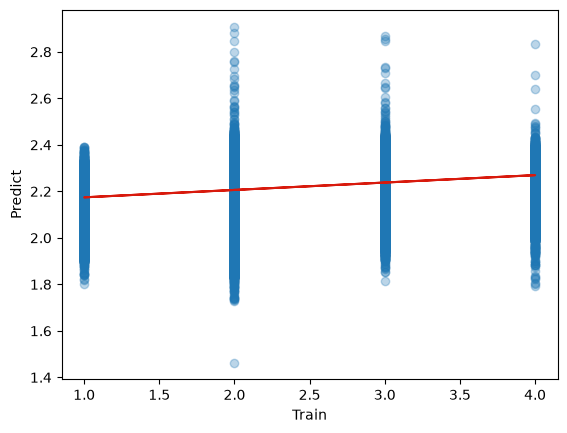

In [80]:
plt.scatter(x=y_train, y=y_lr_train_pred, alpha=0.3)
plt.ylabel("Predict")
plt.xlabel("Train")

z = np.polyfit(y_train, y_lr_train_pred, 1)
p = np.poly1d(z)

plt.plot(y_train, p(y_train), "#D81A0D")